# Policy lab — designing the laws

The physics package fixes the *bookkeeping* (integrator, contacts, conservation, ledger, plots). This lab
leaves the *laws* open. Two slots drive everything:

```python
policy_external = ...   # who is drawn to whom            -> forces between particles
policy_internal = ...   # what happens inside / on contact -> clocks, merge, bounce, emission
result = simulate(particles, external=policy_external, internal=policy_internal, ...)
```

Plug in `ElectromagneticPolicy()` and the system *is* electromagnetism. Anything else is a hypothesis you
can test with the same engine, ledger and plots. Because mechanics conserve whatever a policy decides, a
policy can be wrong about physics without silently breaking the books.

In [1]:
import numpy as np
import pandas as pd
from dataclasses import dataclass

from stochastics.physics import *
from stochastics.physics.policies import *

## 1. Spin and polarity clocks

Each particle has a clock. **spin** is its speed (θ-like), **polarity** its signed amplitude (charge-like).
The value other particles feel is `polarity_now = polarity · waveform(phase)`, with
`phase += spin · dt / 4` per step. With polarity −1, spin 0.5 and dt = 1 the triangle waveform reproduces
the sequence from the brief:

In [8]:
tau = 40
pd.DataFrame({'t': range(tau+1), 'polarity_now': polarity_sequence(polarity=-1, spin=0.05, steps=tau)}).T

,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,40
t,0.0,1.00,2.0,3.00,4.0,5.00,6.0,7.00,8.0,9.00,...,31.00,32.0,33.00,34.0,35.00,36.0,37.00,38.0,39.00,40.0
polarity_now,-1.0,-0.95,-0.9,-0.85,-0.8,-0.75,-0.7,-0.65,-0.6,-0.55,...,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95,1.0


`energy` stays the particle's internal energy reservoir (collision heat goes in, emission spends it), so the
energy ledger keeps balancing; the cycling value lives in `polarity_now`. Waveforms: `'triangle'` (default),
`'cosine'`, `'square'`.

In [9]:
particles = ParticleSystem.random(
    n=160, preset='em', seed=210, dimension=3, random_phase=True,
    clusters=[Cluster(mean=[0, 0, 0], std=0.8), Cluster(mean=[2.0, -1.0, 0], std=0.6)])
particles.charge[:] = 0.0          # only the clocks drive attraction in this lab
particles.spin[:] = np.random.default_rng(1).choice([0.25, 0.5, 1.0], particles.n_live)
particles[0]

Particle(id=0, species='em', mass=1.696, charge=0, radius=0.05576, spin=0.5, polarity=0.5, polarity_now=0.2912, energy=0, position=[-0.2314, 0.5363, 0.1191], velocity=[-0.2137, 0.2223, -0.1583], composition={+:3}, cluster_id=0, active=True)

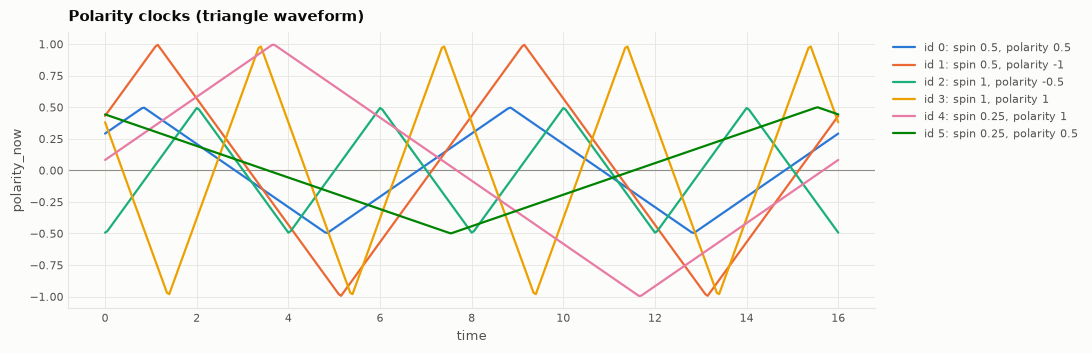

In [10]:
plot_polarity_clocks(particles, duration=16)

## 2. Sanity anchor: the EM policy *is* Coulomb

Same particles, same engine: once with the built-in `Coulomb` law, once with `ElectromagneticPolicy` as the
external policy. The trajectories agree to the last bit.

In [11]:
charged = ParticleSystem.random(n=80, preset='em', seed=5, dimension=3)
a = simulate(charged.copy(), law=Coulomb(k=0.2), steps=400, dt=0.01, record_every=40)
b = simulate(charged.copy(), external=ElectromagneticPolicy(k=0.2), steps=400, dt=0.01, record_every=40)
print('max |Δposition| =', np.abs(a.history[['x', 'y', 'z']].to_numpy() - b.history[['x', 'y', 'z']].to_numpy()).max())

max |Δposition| = 0.0


## 3. Starting hypothesis: opposites attract, with clocks

`OppositesAttract` sets affinity `A_ij = −p_i(t)·p_j(t)` (optionally plus static charge and anti-phase
terms). As clocks drift in and out of step, a pair attracts, goes neutral, then repels. The clocks pump
energy in and out of the system; that work is booked in the **`drive`** ledger, so the accounted energy
still stays flat. Starting cold with drag lets the system settle — with a potential plus friction, the
dynamics descends the policy's energy landscape (the "optimising" behaviour), while the clocks keep
reshaping that landscape. Opposite pairs that touch slowly enough are captured into composites.

,value
metric,
simulated time,0 -> 30
steps x dt,3000 x 0.01
runtime,4.29 s
particles (live),160 -> 98
events: merge,62
events: inelastic,24
events: elastic,9
mass drift,+0.000e+00
charge drift,+0.000e+00


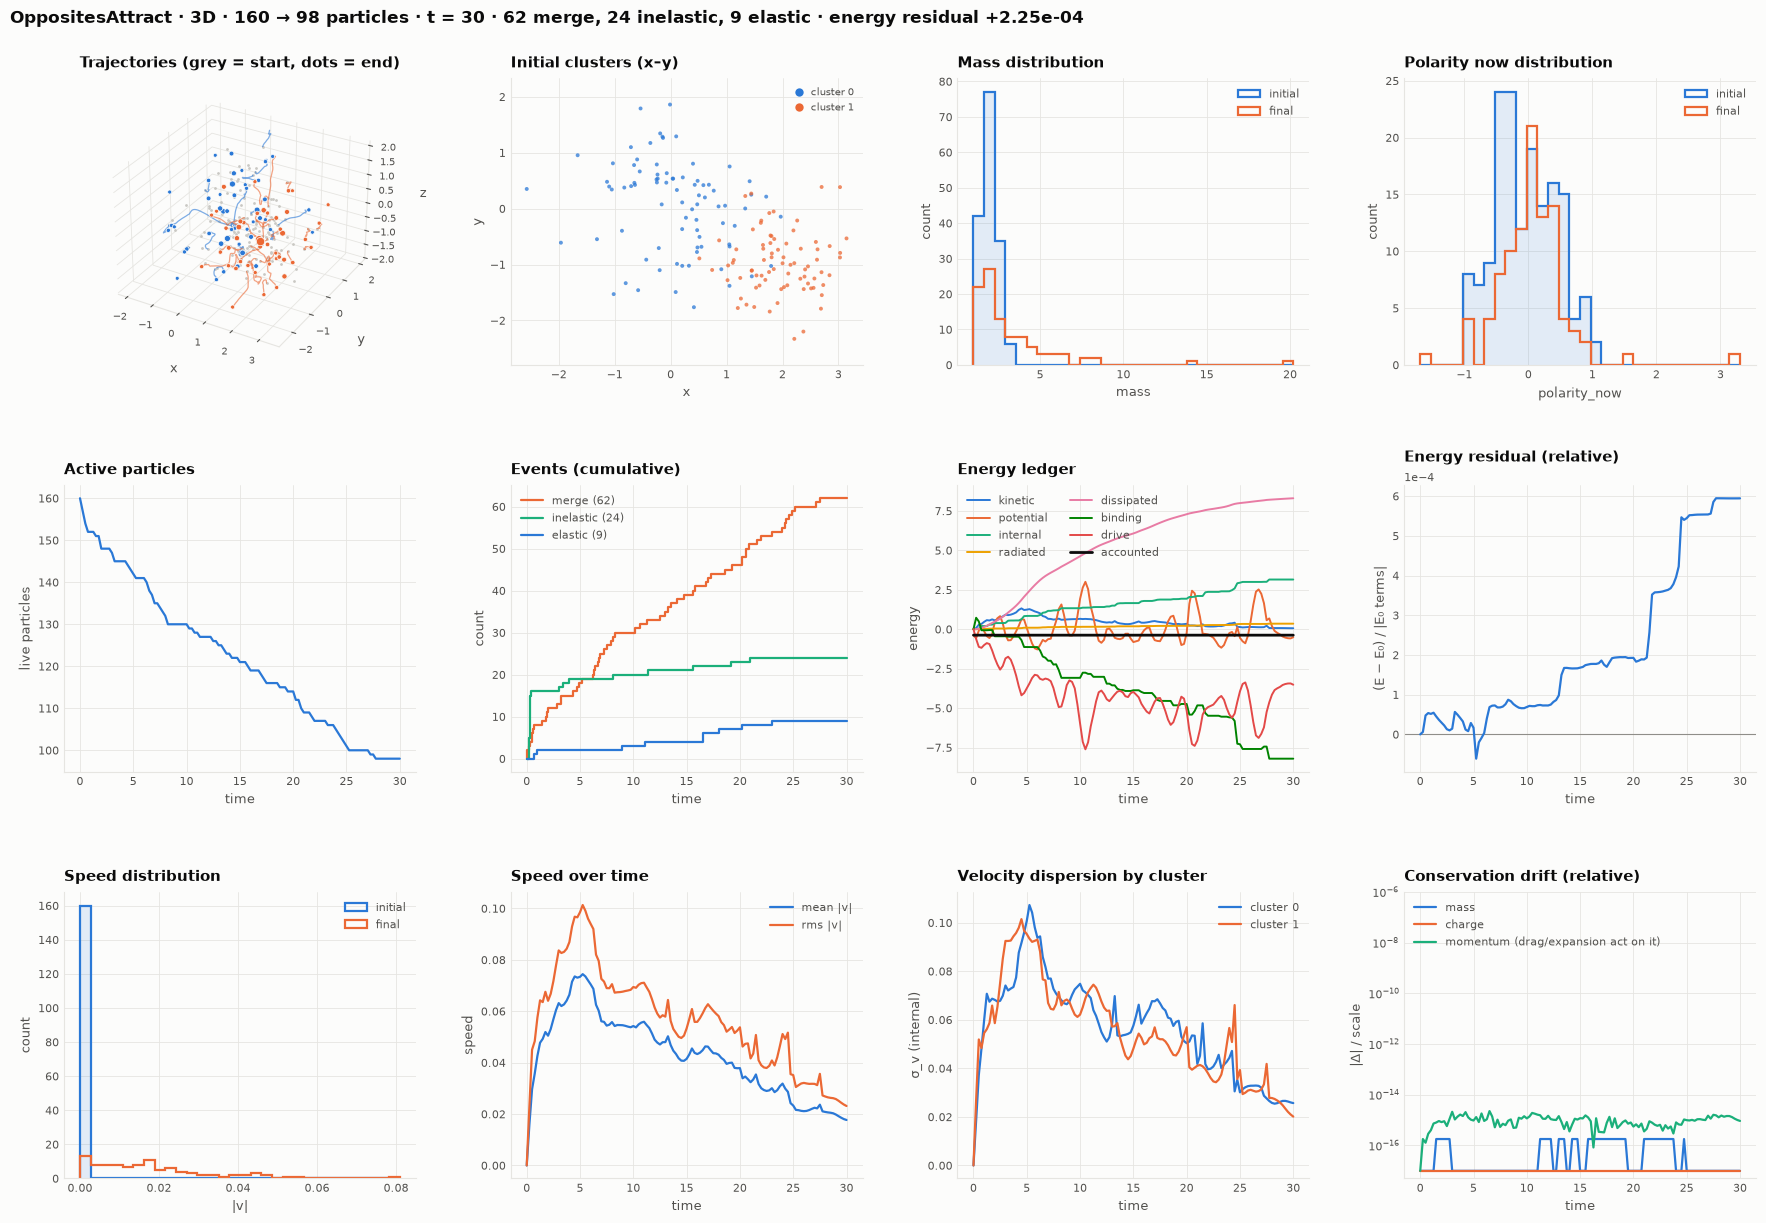

In [12]:
particles.velocity[:] = 0.0                                   # cold start
policy_external = OppositesAttract(strength=0.05, softening=0.1)
policy_internal = InternalPolicy(bond_speed=0.3)

result = simulate(particles, external=policy_external, internal=policy_internal,
                  rules=[Drag(gamma=0.3)], steps=3000, dt=0.01, record_every=25)
report(result)

In [13]:
animate_3d(result, max_frames=80, color_by='polarity_now')

## 4. Write your own

Override one method per idea. Below: an external policy that adds a short-range "same-spin" preference on top
of opposite polarity, and an internal policy where particles that bounce **phase-lock** their clocks
(a Kuramoto-like rule). Both are a few lines; conservation is still guaranteed by the mechanics.

In [14]:
@dataclass
class OppositePolaritySameSpin(ExternalPolicy):
    spin_weight: float = 0.5

    def affinity(self, a, b):
        polarity = -np.outer(a.polarity_now, b.polarity_now)        # opposites attract
        same_spin = np.isclose(a.spin[:, None], b.spin[None, :])    # kin attract a little
        return polarity + self.spin_weight * same_spin


@dataclass
class PhaseLocking(InternalPolicy):
    coupling: float = 0.5        # 0 = independent clocks, 1 = fully synchronise on contact

    def decide(self, state, contact, t):
        outcome = super().decide(state, contact, t)
        if outcome.kind == 'bounce':
            i, j = contact.i, contact.j
            gap = (state.phase[j] - state.phase[i] + 0.5) % 1.0 - 0.5
            state.phase[i] += 0.5 * self.coupling * gap
            state.phase[j] -= 0.5 * self.coupling * gap
            state.touch()           # tell the engine charges changed -> energy re-booked
        return outcome


lab = ParticleSystem.random(n=160, preset='em', seed=3, dimension=2, random_phase=True,
                            clusters=[Cluster(mean=[0, 0], std=1.0)])
lab.charge[:] = 0.0
lab.radius[:] = 0.05
custom = simulate(lab, external=OppositePolaritySameSpin(strength=0.02, softening=0.1),
                  internal=PhaseLocking(coupling=0.6, bond_speed=0.2),
                  rules=[Drag(gamma=0.1)], steps=2500, dt=0.01, record_every=25)
custom.summary()

,value
metric,
simulated time,0 -> 25
steps x dt,2500 x 0.01
runtime,4.20 s
particles (live),160 -> 33
events: inelastic,180
events: merge,127
events: elastic,27
mass drift,-5.684e-14
charge drift,+0.000e+00


In [15]:
animate_2d(custom, max_frames=80, color_by='polarity_now', trail=5)

## 5. Emission and absorption

`ThermalEmission` is an example internal policy: collisions heat particles; when a composite's internal
energy per unit mass passes a threshold it **emits** its least-bound constituent (with recoil), and quanta
captured by other particles are logged as **absorb**. Every step of that cycle is in the ledger.

In [16]:
hot = ParticleSystem.random(n=100, preset='em', seed=7, dimension=2)
emission = simulate(hot, external=OppositesAttract(strength=0.05, softening=0.1),
                    internal=ThermalEmission(threshold=0.02, release=0.5),
                    steps=1500, dt=0.01, record_every=25)
display(emission.event_counts().to_frame().T)
emission.summary()

event,emit,inelastic,elastic,absorb,merge
count,243,96,72,67,36


,value
metric,
simulated time,0 -> 15
steps x dt,1500 x 0.01
runtime,6.53 s
particles (live),100 -> 240
events: emit,243
events: inelastic,96
events: elastic,72
events: absorb,67
events: merge,36


## 6. Toward agents: non-reciprocal policies

Nothing in the engine requires Newton's third law. Setting `reciprocal=False` allows A to chase B while B
flees A — predator/prey, or traders chasing liquidity that moves away. There is no potential then, so the
energy residual is reported as *n/a*, but momentum/mass bookkeeping and all plots still work. A Gaussian
kernel makes the interaction local, as it usually is for agents.

In [17]:
@dataclass
class ChaseAndEvade(ExternalPolicy):
    def affinity(self, a, b):
        predator_a = (a.cluster_id == 0)[:, None]
        predator_b = (b.cluster_id == 0)[None, :]
        return np.where(predator_a & ~predator_b, 1.0,          # predators chase prey
               np.where(~predator_a & predator_b, -1.5,         # prey flee predators
               np.where(predator_a & predator_b, -0.2, 0.3)))   # predators spread out, prey flock

herd = ParticleSystem.random(n=120, seed=4, dimension=2, clusters=[
    Cluster(mean=[-2, 0], std=0.4, weight=0.15), Cluster(mean=[1, 0], std=1.0, weight=0.85)])
chase = simulate(herd, external=ChaseAndEvade(strength=0.3, kernel=Gaussian(length=0.8), reciprocal=False),
                 rules=[Drag(gamma=0.6)], steps=1500, dt=0.01, record_every=15)
animate_2d(chase, max_frames=80, color_by='cluster', trail=6)

## Where to take it next

* **External policy:** distance-dependent sign changes (attract far / repel near) via a custom `Kernel`;
  affinities that depend on internal energy; learnable affinity matrices fitted to observed trajectories.
* **Internal policy:** rules for how spin and polarity combine on merge (`combine`), energy-dependent spin,
  decay chains (`emit` with several constituent types), phase-locking as an interaction in its own right.
  `InternalPolicy(allow_merge=False)` keeps the restitution gradient but never fuses particles.
* **Agents:** replace `polarity_now` with any state (inventory, attention, opinion) and the same machinery
  runs population, market or attention dynamics — the ledger then becomes a budget of the conserved quantity.